# Day 1 — Setup & Download PTB-XL

Run each cell below **in order**, top to bottom. Don't skip any.

If a cell throws an error, stop and copy-paste the full error message back into the chat — don't try to fix it yourself first.

## Cell 1 — Connect this notebook to your Google Drive

This will pop up a login/permission window. Click through it and allow access.

Why: Colab deletes everything on its local disk when you disconnect or the session times out. Google Drive doesn't get deleted, so we download data straight into Drive and it stays there for tomorrow.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cell 2 — Create a project folder in your Drive

This makes a folder called `ecg_project` inside your Drive (under `MyDrive`), and a `data` subfolder where the ECG files will live. Everything for this project goes in here from now on.

In [ ]:
import os

PROJECT_DIR = '/content/drive/MyDrive/ecg_project'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')

os.makedirs(DATA_DIR, exist_ok=True)
print('Project folder ready at:', PROJECT_DIR)
print('Data will download into:', DATA_DIR)

Project folder ready at: /content/drive/MyDrive/ecg_project
Data will download into: /content/drive/MyDrive/ecg_project/data


## Cell 3 — Download the PTB-XL metadata files (small, fast)

These two CSV files contain the diagnosis labels for every ECG recording. We need them before the actual waveform files are useful.

This should take a few seconds.

In [ ]:
!wget -N -c -P {DATA_DIR} https://physionet.org/files/ptb-xl/1.0.3/ptbxl_database.csv
!wget -N -c -P {DATA_DIR} https://physionet.org/files/ptb-xl/1.0.3/scp_statements.csv

--2026-09-07 18:29:00--  https://physionet.org/files/ptb-xl/1.0.3/ptbxl_database.csv
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 304 Not Modified
File ‘/content/drive/MyDrive/ecg_project/data/ptbxl_database.csv’ not modified on server. Omitting download.

--2026-09-07 18:29:01--  https://physionet.org/files/ptb-xl/1.0.3/scp_statements.csv
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 304 Not Modified
File ‘/content/drive/MyDrive/ecg_project/data/scp_statements.csv’ not modified on server. Omitting download.



## Cell 4 — Download the 100Hz waveform files (the actual ECG signals)

This is the big download — roughly 1-2 GB and can take 10-20+ minutes depending on Colab's connection. This is normal, let it run.

`-r` = recursive (grabs the whole folder), `-N` = skip files already downloaded, `-c` = resume if interrupted, `-np` = don't wander into parent folders.

If your Colab session disconnects partway through, just re-run this exact cell — `-c` and `-N` mean it will pick up where it left off instead of starting over.

In [ ]:
#!wget -r -N -c -np -nH --cut-dirs=3 -P {DATA_DIR} https://physionet.org/files/ptb-xl/1.0.3/records100/

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/ecg_project'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')

import numpy as np
X = np.load(os.path.join(DATA_DIR, 'X_processed.npy'))
Y = np.load(os.path.join(DATA_DIR, 'Y_labels.npy'))

print('X shape:', X.shape)
print('Y shape:', Y.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
X shape: (21388, 1000, 12)
Y shape: (21388, 5)


In [ ]:
import pandas as pd

fold_df = pd.read_csv(os.path.join(DATA_DIR, 'fold_assignments.csv'), index_col='ecg_id')
fold = fold_df['strat_fold'].values

train_mask = fold <= 8
val_mask = fold == 9
test_mask = fold == 10

X_train, Y_train = X[train_mask], Y[train_mask]
X_val, Y_val = X[val_mask], Y[val_mask]
X_test, Y_test = X[test_mask], Y[test_mask]

print('Train:', X_train.shape, Y_train.shape)
print('Val:  ', X_val.shape, Y_val.shape)
print('Test: ', X_test.shape, Y_test.shape)

Train: (17084, 1000, 12) (17084, 5)
Val:   (2146, 1000, 12) (2146, 5)
Test:  (2158, 1000, 12) (2158, 5)


## Cell 5 — Verify the download actually worked

This counts how many files landed in your Drive folder. PTB-XL's 100Hz set should give roughly 21,000+ record files (each recording has 2 files: `.hea` and `.dat`).

In [ ]:
import glob

hea_files = glob.glob(os.path.join(DATA_DIR, 'records100', '**', '*.hea'), recursive=True)
dat_files = glob.glob(os.path.join(DATA_DIR, 'records100', '**', '*.dat'), recursive=True)

print(f'Found {len(hea_files)} .hea files and {len(dat_files)} .dat files')

if len(hea_files) < 20000:
    print('\n⚠️  This looks low — the download may still be running or got interrupted. Re-run Cell 4.')
else:
    print('\n✅ Looks complete.')

Found 21799 .hea files and 21799 .dat files

✅ Looks complete.


## Cell 6 — Install the library needed to read ECG files

PTB-XL is stored in a medical waveform format called WFDB. `wfdb` is the Python library that reads it.

In [ ]:
!pip install wfdb -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 15.1 MB/s eta 0:00:00


## Cell 7 — Load the labels and check them

This loads `ptbxl_database.csv` (the labels) into a table so we can look at it. You should see columns like `ecg_id`, `patient_id`, `age`, `sex`, `scp_codes`, `strat_fold`, and a `filename_lr` column pointing to each 100Hz recording.

In [ ]:
import pandas as pd

labels_df = pd.read_csv(os.path.join(DATA_DIR, 'ptbxl_database.csv'), index_col='ecg_id')
print(f'Loaded {len(labels_df)} label rows')
labels_df.head()

Loaded 21799 label rows


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


## Cell 8 — Load ONE actual ECG recording and plot it

This is the real test: can we actually read a waveform file and see a heartbeat? If this plot shows something that looks like an ECG (spiky waveform), Day 1 is done.

Signal shape (samples, leads): (1000, 12)
Lead names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


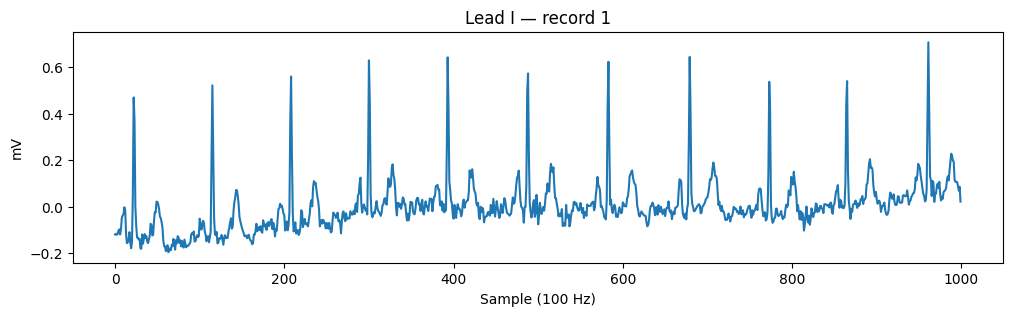

In [ ]:
import wfdb
import matplotlib.pyplot as plt

# Grab the very first record's filename from the labels table
first_record_relpath = labels_df.iloc[0]['filename_lr']  # e.g. 'records100/00000/00001_lr'
record_path = os.path.join(DATA_DIR, first_record_relpath)

record = wfdb.rdrecord(record_path)
signal = record.p_signal  # shape: (samples, 12 leads)

print('Signal shape (samples, leads):', signal.shape)
print('Lead names:', record.sig_name)

plt.figure(figsize=(12, 3))
plt.plot(signal[:, 0])  # plot lead I (first lead)
plt.title(f'Lead I — record {labels_df.index[0]}')
plt.xlabel('Sample (100 Hz)')
plt.ylabel('mV')
plt.show()

---
## Day 1 checklist
- [ ] Cell 5 printed "✅ Looks complete."
- [ ] Cell 8 showed a plot that looks like a heartbeat waveform (spiky, repeating pattern)

If both of those are true, Day 1 is done. Come back to the chat and tell me it worked (or paste any error), and we'll build Day 2 next: understanding the label structure and building the official train/val/test split.

## **Day 2**

In [ ]:
import ast

labels_df['scp_codes'] = labels_df['scp_codes'].apply(ast.literal_eval)
labels_df['scp_codes'].head()

,scp_codes
ecg_id,
1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
2,"{'NORM': 80.0, 'SBRAD': 0.0}"
3,"{'NORM': 100.0, 'SR': 0.0}"
4,"{'NORM': 100.0, 'SR': 0.0}"
5,"{'NORM': 100.0, 'SR': 0.0}"


In [ ]:
scp_df = pd.read_csv(os.path.join(DATA_DIR, 'scp_statements.csv'), index_col=0)
scp_df = scp_df[scp_df['diagnostic'] == 1]  # keep only diagnostic codes, drop form/rhythm-only codes

print(f'{len(scp_df)} diagnostic codes map to these superclasses:')
print(scp_df['diagnostic_class'].value_counts())

44 diagnostic codes map to these superclasses:
diagnostic_class
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64


In [ ]:
def codes_to_superclasses(scp_dict):
    classes = set()
    for code in scp_dict.keys():
        if code in scp_df.index:
            classes.add(scp_df.loc[code, 'diagnostic_class'])
    return list(classes)

labels_df['superclasses'] = labels_df['scp_codes'].apply(codes_to_superclasses)

# Drop any record that ended up with zero mapped superclasses (rare, but happens)
labels_df = labels_df[labels_df['superclasses'].apply(len) > 0]
print(f'{len(labels_df)} records have at least one valid superclass label')

21388 records have at least one valid superclass label


In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(labels_df['superclasses'])

print('Classes, in column order:', mlb.classes_)
print('Label matrix shape:', Y.shape)  # (num_records, 5)
print('Example row:', Y[0], '→', labels_df['superclasses'].iloc[0])

Classes, in column order: ['CD' 'HYP' 'MI' 'NORM' 'STTC']
Label matrix shape: (21388, 5)
Example row: [0 0 0 1 0] → ['NORM']


In [ ]:
train_mask = labels_df['strat_fold'] <= 8
val_mask = labels_df['strat_fold'] == 9
test_mask = labels_df['strat_fold'] == 10

train_df, Y_train = labels_df[train_mask], Y[train_mask.values]
val_df, Y_val = labels_df[val_mask], Y[val_mask.values]
test_df, Y_test = labels_df[test_mask], Y[test_mask.values]

print(f'Train: {len(train_df)} records')
print(f'Val:   {len(val_df)} records')
print(f'Test:  {len(test_df)} records')

Train: 17084 records
Val:   2146 records
Test:  2158 records


## **Day 3**

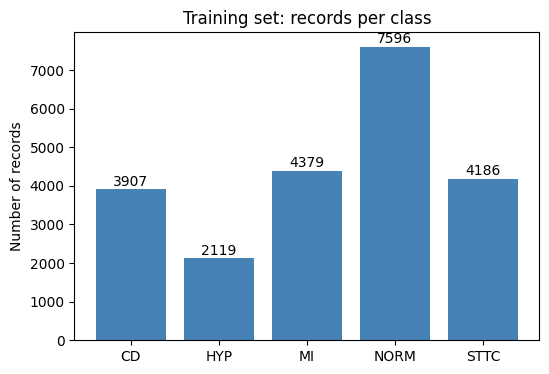

Class balance (%): [22.9 12.4 25.6 44.5 24.5]


In [ ]:
import matplotlib.pyplot as plt

class_counts = Y_train.sum(axis=0)
class_names = mlb.classes_

plt.figure(figsize=(6, 4))
plt.bar(class_names, class_counts, color='steelblue')
plt.title('Training set: records per class')
plt.ylabel('Number of records')
for i, count in enumerate(class_counts):
    plt.text(i, count + 100, str(count), ha='center')
plt.show()

print('Class balance (%):', (class_counts / len(Y_train) * 100).round(1))

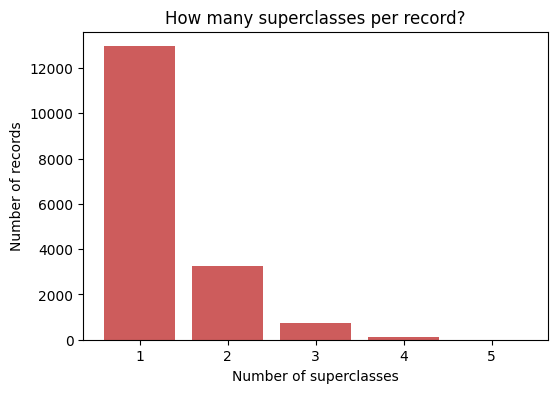

24.2% of records have more than one diagnosis at once


In [ ]:
labels_per_record = Y_train.sum(axis=1)

plt.figure(figsize=(6, 4))
plt.hist(labels_per_record, bins=[1,2,3,4,5,6], align='left', rwidth=0.8, color='indianred')
plt.title('How many superclasses per record?')
plt.xlabel('Number of superclasses')
plt.ylabel('Number of records')
plt.xticks([1,2,3,4,5])
plt.show()

multi_label_pct = (labels_per_record > 1).mean() * 100
print(f'{multi_label_pct:.1f}% of records have more than one diagnosis at once')

In [ ]:
import wfdb

# Check a random sample of 50 records instead of all 21,388 — fast, and enough to catch systemic issues
sample_ids = train_df.sample(50, random_state=42).index

shapes = []
for ecg_id in sample_ids:
    rel_path = labels_df.loc[ecg_id, 'filename_lr']
    record = wfdb.rdrecord(os.path.join(DATA_DIR, rel_path))
    shapes.append(record.p_signal.shape)

unique_shapes = set(shapes)
print('Unique (samples, leads) shapes found:', unique_shapes)

Unique (samples, leads) shapes found: {(1000, 12)}


In [ ]:
nan_count = 0
for ecg_id in sample_ids:
    rel_path = labels_df.loc[ecg_id, 'filename_lr']
    record = wfdb.rdrecord(os.path.join(DATA_DIR, rel_path))
    if record.p_signal is None or pd.isna(record.p_signal).any():
        nan_count += 1
        print(f'Record {ecg_id} has missing values')

print(f'{nan_count} out of {len(sample_ids)} sampled records have NaN values')

0 out of 50 sampled records have NaN values


## **Day 4**

In [ ]:
from scipy.signal import butter, filtfilt
import numpy as np

def bandpass_filter(signal, fs=100, lowcut=0.5, highcut=40, order=4):
    nyquist = fs / 2
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    # Apply along the time axis (axis=0) independently for each of the 12 leads
    filtered = filtfilt(b, a, signal, axis=0)
    return filtered

In [ ]:
def normalize_signal(signal):
    # Normalize each of the 12 leads independently (mean 0, std 1)
    mean = signal.mean(axis=0, keepdims=True)
    std = signal.std(axis=0, keepdims=True)
    std[std == 0] = 1e-8  # avoid divide-by-zero on a flat/dead lead
    return (signal - mean) / std

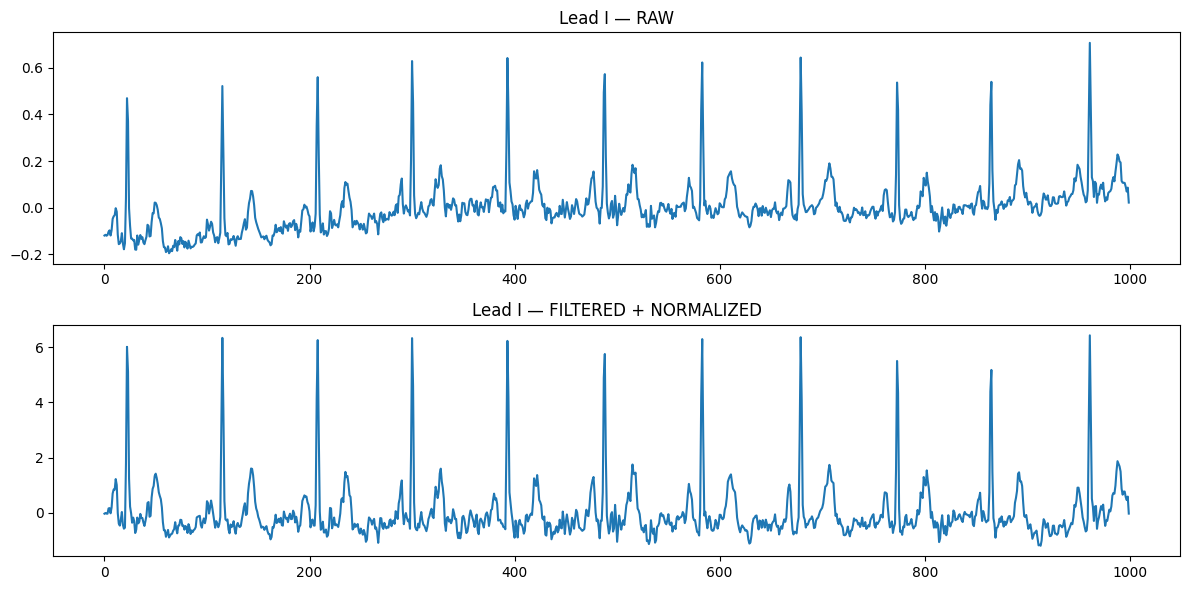

In [ ]:
def preprocess_record(ecg_id):
    rel_path = labels_df.loc[ecg_id, 'filename_lr']
    record = wfdb.rdrecord(os.path.join(DATA_DIR, rel_path))
    signal = record.p_signal
    signal = bandpass_filter(signal)
    signal = normalize_signal(signal)
    return signal

# Test on record 1, the same one from your Day 1 plot
raw_record = wfdb.rdrecord(os.path.join(DATA_DIR, labels_df.loc[1, 'filename_lr']))
raw_signal = raw_record.p_signal
clean_signal = preprocess_record(1)

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(raw_signal[:, 0])
axes[0].set_title('Lead I — RAW')
axes[1].plot(clean_signal[:, 0])
axes[1].set_title('Lead I — FILTERED + NORMALIZED')
plt.tight_layout()
plt.show()

In [ ]:
import time

sample_ids = train_df.sample(200, random_state=42).index
start = time.time()
for ecg_id in sample_ids:
    _ = preprocess_record(ecg_id)
elapsed = time.time() - start

print(f'{elapsed:.2f} sec for 200 records → estimated {elapsed / 200 * len(labels_df):.1f} sec for all {len(labels_df)} records')

224.49 sec for 200 records → estimated 24007.4 sec for all 21388 records


In [ ]:
'''
import numpy as np
from tqdm import tqdm

all_ids = labels_df.index.tolist()
X = np.zeros((len(all_ids), 1000, 12), dtype=np.float32)

for i, ecg_id in enumerate(tqdm(all_ids)):
    X[i] = preprocess_record(ecg_id)

print('X shape:', X.shape)  # should be (21388, 1000, 12)
'''

"\nimport numpy as np\nfrom tqdm import tqdm\n\nall_ids = labels_df.index.tolist()\nX = np.zeros((len(all_ids), 1000, 12), dtype=np.float32)\n\nfor i, ecg_id in enumerate(tqdm(all_ids)):\n    X[i] = preprocess_record(ecg_id)\n\nprint('X shape:', X.shape)  # should be (21388, 1000, 12)\n"

In [ ]:
import numpy as np

X = np.load(os.path.join(DATA_DIR, 'X_processed.npy'))
Y = np.load(os.path.join(DATA_DIR, 'Y_labels.npy'))

print('X shape:', X.shape)
print('Y shape:', Y.shape)

X shape: (21388, 1000, 12)
Y shape: (21388, 5)


In [ ]:
np.save(os.path.join(DATA_DIR, 'X_processed.npy'), X)
np.save(os.path.join(DATA_DIR, 'Y_labels.npy'), Y)

# Save the fold assignment too, so tomorrow you can reload and re-split without recomputing anything
labels_df[['strat_fold']].to_csv(os.path.join(DATA_DIR, 'fold_assignments.csv'))

print('Saved. File sizes:')
!ls -lh {DATA_DIR}/X_processed.npy {DATA_DIR}/Y_labels.npy

Saved. File sizes:
-rw------- 1 root root 980M Sep  7 18:37 /content/drive/MyDrive/ecg_project/data/X_processed.npy
-rw------- 1 root root 836K Sep  7 18:37 /content/drive/MyDrive/ecg_project/data/Y_labels.npy


In [ ]:
fold = labels_df['strat_fold'].values

train_mask = fold <= 8
val_mask = fold == 9
test_mask = fold == 10

X_train, Y_train = X[train_mask], Y[train_mask]
X_val, Y_val = X[val_mask], Y[val_mask]
X_test, Y_test = X[test_mask], Y[test_mask]

print('Train:', X_train.shape, Y_train.shape)
print('Val:  ', X_val.shape, Y_val.shape)
print('Test: ', X_test.shape, Y_test.shape)

Train: (17084, 1000, 12) (17084, 5)
Val:   (2146, 1000, 12) (2146, 5)
Test:  (2158, 1000, 12) (2158, 5)


## **Day 6**

In [ ]:
def extract_features(signal):
    # signal shape: (1000, 12)
    features = []
    for lead in range(12):
        lead_signal = signal[:, lead]
        features.extend([
            lead_signal.mean(),
            lead_signal.std(),
            lead_signal.min(),
            lead_signal.max(),
            np.percentile(lead_signal, 25),
            np.percentile(lead_signal, 75),
        ])
    return features

# 12 leads × 6 stats each = 72 features per record

In [ ]:
from tqdm import tqdm

def build_feature_matrix(X_signals):
    return np.array([extract_features(X_signals[i]) for i in tqdm(range(len(X_signals)))])

X_train_feat = build_feature_matrix(X_train)
X_val_feat = build_feature_matrix(X_val)
X_test_feat = build_feature_matrix(X_test)

print('Feature matrix shapes:', X_train_feat.shape, X_val_feat.shape, X_test_feat.shape)

100%|██████████| 2158/2158 [00:06<00:00, 310.08it/s]

Feature matrix shapes: (17084, 72) (2146, 72) (2158, 72)


In [ ]:
!pip install xgboost -q

from xgboost import XGBClassifier
from sklearn.multioutput import MultiOutputClassifier

base_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    eval_metric='logloss',
    random_state=42
)

multi_model = MultiOutputClassifier(base_model)
multi_model.fit(X_train_feat, Y_train)

print('Baseline model trained.')

Baseline model trained.


## **Day 7**

In [ ]:
from sklearn.metrics import roc_auc_score, f1_score

Y_val_pred_proba = np.array([est.predict_proba(X_val_feat)[:, 1] for est in multi_model.estimators_]).T
Y_val_pred_binary = (Y_val_pred_proba > 0.5).astype(int)

macro_auroc = roc_auc_score(Y_val, Y_val_pred_proba, average='macro')
macro_f1 = f1_score(Y_val, Y_val_pred_binary, average='macro')

print(f'Baseline macro-AUROC: {macro_auroc:.3f}')
print(f'Baseline macro-F1:    {macro_f1:.3f}')

# Per-class breakdown — useful to see which conditions are easy vs hard even for the baseline
per_class_auroc = roc_auc_score(Y_val, Y_val_pred_proba, average=None)
for cls, auroc in zip(mlb.classes_, per_class_auroc):
    print(f'  {cls}: AUROC = {auroc:.3f}')

Baseline macro-AUROC: 0.836
Baseline macro-F1:    0.539
  CD: AUROC = 0.855
  HYP: AUROC = 0.736
  MI: AUROC = 0.827
  NORM: AUROC = 0.891
  STTC: AUROC = 0.870


In [ ]:
import json

baseline_results = {
    'macro_auroc': float(macro_auroc),
    'macro_f1': float(macro_f1),
    'per_class_auroc': {cls: float(a) for cls, a in zip(mlb.classes_, per_class_auroc)}
}

with open(os.path.join(DATA_DIR, 'baseline_results.json'), 'w') as f:
    json.dump(baseline_results, f, indent=2)

print('Saved baseline results.')

Saved baseline results.


## **Day 8**

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


In [ ]:
class ECGDataset(Dataset):
    def __init__(self, X, Y):
        # X: (num_records, 1000, 12) -> transpose to (num_records, 12, 1000)
        self.X = torch.tensor(X, dtype=torch.float32).permute(0, 2, 1)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

train_dataset = ECGDataset(X_train, Y_train)
val_dataset = ECGDataset(X_val, Y_val)
test_dataset = ECGDataset(X_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Sanity check
sample_x, sample_y = next(iter(train_loader))
print('Batch X shape:', sample_x.shape)  # should be (64, 12, 1000)
print('Batch Y shape:', sample_y.shape)  # should be (64, 5)

Batch X shape: torch.Size([64, 12, 1000])
Batch Y shape: torch.Size([64, 5])


In [ ]:
class ECG1DCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.conv1 = nn.Conv1d(in_channels=12, out_channels=32, kernel_size=7, padding=3)
        self.bn1 = nn.BatchNorm1d(32)

        self.conv2 = nn.Conv1d(32, 64, kernel_size=5, padding=2)
        self.bn2 = nn.BatchNorm1d(64)

        self.conv3 = nn.Conv1d(64, 128, kernel_size=5, padding=2)
        self.bn3 = nn.BatchNorm1d(128)

        self.conv4 = nn.Conv1d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm1d(256)

        self.pool = nn.MaxPool1d(kernel_size=2)
        self.global_pool = nn.AdaptiveAvgPool1d(1)  # collapses the time dimension to 1 value per channel

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = self.global_pool(x).squeeze(-1)  # shape: (batch, 256)
        x = self.dropout(x)
        x = self.fc(x)  # shape: (batch, num_classes) — raw scores, sigmoid applied later in the loss function
        return x

model = ECG1DCNN(num_classes=5).to(device)
print(model)

ECG1DCNN(
  (conv1): Conv1d(12, 32, kernel_size=(7,), stride=(1,), padding=(3,))
  (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (bn4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (global_pool): AdaptiveAvgPool1d(output_size=1)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=5, bias=True)
)


In [ ]:
model.eval()
with torch.no_grad():
    sample_x = sample_x.to(device)
    output = model(sample_x)
    print('Model output shape:', output.shape)  # should be (64, 5)

Model output shape: torch.Size([64, 5])


## **Day 9**

In [ ]:
# Calculate positive class weights: (negative count / positive count) for each class
pos_counts = Y_train.sum(axis=0)
neg_counts = len(Y_train) - pos_counts
pos_weights = torch.tensor(neg_counts / pos_counts, dtype=torch.float32).to(device)

print('Class weights (higher = rarer class, penalized more):')
for cls, w in zip(mlb.classes_, pos_weights.cpu().numpy()):
    print(f'  {cls}: {w:.2f}')

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)

Class weights (higher = rarer class, penalized more):
  CD: 3.37
  HYP: 7.06
  MI: 2.90
  NORM: 1.25
  STTC: 3.08


In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for X_batch, Y_batch in loader:
        X_batch, Y_batch = X_batch.to(device), Y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, Y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    return total_loss / len(loader.dataset)

In [ ]:
from sklearn.metrics import roc_auc_score

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, Y_batch in loader:
            X_batch, Y_batch = X_batch.to(device), Y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, Y_batch)
            total_loss += loss.item() * X_batch.size(0)

            probs = torch.sigmoid(outputs).cpu().numpy()
            all_preds.append(probs)
            all_targets.append(Y_batch.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)
    macro_auroc = roc_auc_score(all_targets, all_preds, average='macro')

    return total_loss / len(loader.dataset), macro_auroc

In [ ]:
import time

NUM_EPOCHS = 3  # small test run first — we'll do the real longer run in Step 6 tomorrow if this works

start = time.time()
for epoch in range(NUM_EPOCHS):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_auroc = evaluate(model, val_loader, criterion, device)
    print(f'Epoch {epoch+1}/{NUM_EPOCHS} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | Val AUROC: {val_auroc:.4f}')

elapsed = time.time() - start
print(f'\n{elapsed:.1f} sec for {NUM_EPOCHS} epochs → ~{elapsed/NUM_EPOCHS:.1f} sec/epoch')

Epoch 1/3 | Train loss: 0.6468 | Val loss: 0.6392 | Val AUROC: 0.8903
Epoch 2/3 | Train loss: 0.5770 | Val loss: 0.6080 | Val AUROC: 0.9018
Epoch 3/3 | Train loss: 0.5555 | Val loss: 0.5886 | Val AUROC: 0.9021

12.4 sec for 3 epochs → ~4.1 sec/epoch


In [ ]:
# Fresh model + optimizer so training starts from scratch, not from the 3-epoch test above
model = ECG1DCNN(num_classes=5).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

NUM_EPOCHS = 50
PATIENCE = 8  # stop early if val AUROC doesn't improve for this many epochs in a row

best_val_auroc = 0
epochs_without_improvement = 0
history = {'train_loss': [], 'val_loss': [], 'val_auroc': []}

best_model_path = os.path.join(DATA_DIR, 'best_model.pt')

start = time.time()
for epoch in range(NUM_EPOCHS):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_auroc = evaluate(model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_auroc'].append(val_auroc)

    improved = val_auroc > best_val_auroc
    if improved:
        best_val_auroc = val_auroc
        epochs_without_improvement = 0
        torch.save(model.state_dict(), best_model_path)
    else:
        epochs_without_improvement += 1

    flag = ' <- best so far, saved' if improved else ''
    print(f'Epoch {epoch+1}/{NUM_EPOCHS} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | Val AUROC: {val_auroc:.4f}{flag}')

    if epochs_without_improvement >= PATIENCE:
        print(f'\nStopped early — no improvement for {PATIENCE} epochs.')
        break

elapsed = time.time() - start
print(f'\nTotal training time: {elapsed:.1f} sec ({elapsed/60:.1f} min)')
print(f'Best val AUROC: {best_val_auroc:.4f}')

Epoch 1/50 | Train loss: 0.6495 | Val loss: 0.6036 | Val AUROC: 0.8964 <- best so far, saved
Epoch 2/50 | Train loss: 0.5754 | Val loss: 0.6113 | Val AUROC: 0.9025 <- best so far, saved
Epoch 3/50 | Train loss: 0.5558 | Val loss: 0.5902 | Val AUROC: 0.9051 <- best so far, saved
Epoch 4/50 | Train loss: 0.5396 | Val loss: 0.5642 | Val AUROC: 0.9094 <- best so far, saved
Epoch 5/50 | Train loss: 0.5251 | Val loss: 0.5867 | Val AUROC: 0.9079
Epoch 6/50 | Train loss: 0.5158 | Val loss: 0.5846 | Val AUROC: 0.9083
Epoch 7/50 | Train loss: 0.5079 | Val loss: 0.5983 | Val AUROC: 0.9087
Epoch 8/50 | Train loss: 0.4991 | Val loss: 0.5912 | Val AUROC: 0.9073
Epoch 9/50 | Train loss: 0.4891 | Val loss: 0.5716 | Val AUROC: 0.9088
Epoch 10/50 | Train loss: 0.4788 | Val loss: 0.5941 | Val AUROC: 0.9104 <- best so far, saved
Epoch 11/50 | Train loss: 0.4717 | Val loss: 0.5968 | Val AUROC: 0.9085
Epoch 12/50 | Train loss: 0.4624 | Val loss: 0.5594 | Val AUROC: 0.9129 <- best so far, saved
Epoch 13/50 |

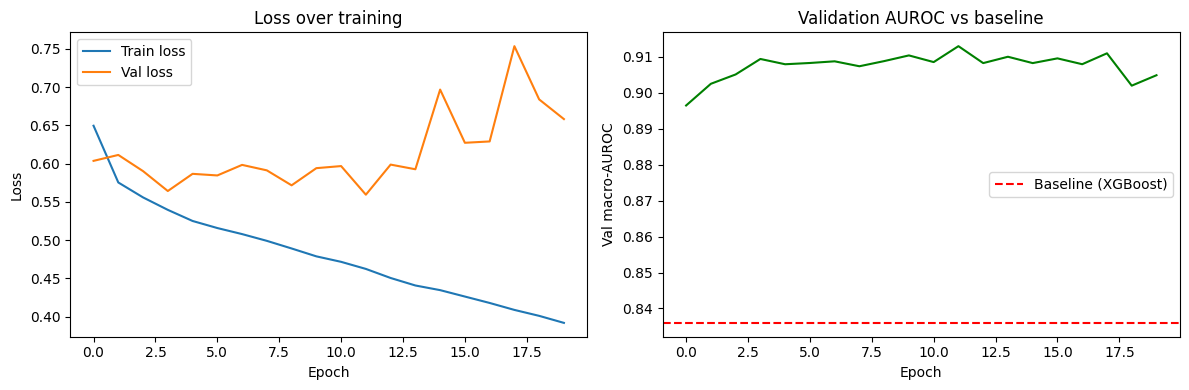

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['train_loss'], label='Train loss')
axes[0].plot(history['val_loss'], label='Val loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss over training')
axes[0].legend()

axes[1].plot(history['val_auroc'], color='green')
axes[1].axhline(y=0.836, color='red', linestyle='--', label='Baseline (XGBoost)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Val macro-AUROC')
axes[1].set_title('Validation AUROC vs baseline')
axes[1].legend()

plt.tight_layout()
plt.show()

## **Day 11**

In [ ]:
# Load a fresh model and restore the best weights saved during training
best_model = ECG1DCNN(num_classes=5).to(device)
best_model.load_state_dict(torch.load(best_model_path))
best_model.eval()

print('Loaded best checkpoint from:', best_model_path)

Loaded best checkpoint from: /content/drive/MyDrive/ecg_project/data/best_model.pt


In [ ]:
from sklearn.metrics import roc_auc_score, f1_score

all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, Y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = best_model(X_batch)
        probs = torch.sigmoid(outputs).cpu().numpy()
        all_preds.append(probs)
        all_targets.append(Y_batch.numpy())

all_preds = np.concatenate(all_preds)
all_targets = np.concatenate(all_targets)

test_macro_auroc = roc_auc_score(all_targets, all_preds, average='macro')
test_preds_binary = (all_preds > 0.5).astype(int)
test_macro_f1 = f1_score(all_targets, test_preds_binary, average='macro')

print(f'TEST macro-AUROC: {test_macro_auroc:.4f}')
print(f'TEST macro-F1:    {test_macro_f1:.4f}')

per_class_test_auroc = roc_auc_score(all_targets, all_preds, average=None)
print('\nPer-class TEST AUROC:')
for cls, auroc in zip(mlb.classes_, per_class_test_auroc):
    print(f'  {cls}: {auroc:.4f}')

TEST macro-AUROC: 0.9102
TEST macro-F1:    0.6880

Per-class TEST AUROC:
  CD: 0.9144
  HYP: 0.8356
  MI: 0.9263
  NORM: 0.9415
  STTC: 0.9330


In [ ]:
baseline_test_pred_proba = np.array([est.predict_proba(X_test_feat)[:, 1] for est in multi_model.estimators_]).T
baseline_test_pred_binary = (baseline_test_pred_proba > 0.5).astype(int)

baseline_test_auroc = roc_auc_score(Y_test, baseline_test_pred_proba, average='macro')
baseline_test_f1 = f1_score(Y_test, baseline_test_pred_binary, average='macro')

print(f'BASELINE TEST macro-AUROC: {baseline_test_auroc:.4f}')
print(f'BASELINE TEST macro-F1:    {baseline_test_f1:.4f}')

print(f'\nCNN improvement over baseline: +{test_macro_auroc - baseline_test_auroc:.4f} AUROC')

BASELINE TEST macro-AUROC: 0.8343
BASELINE TEST macro-F1:    0.5388

CNN improvement over baseline: +0.0759 AUROC


In [ ]:
final_results = {
    'baseline': {
        'test_macro_auroc': float(baseline_test_auroc),
        'test_macro_f1': float(baseline_test_f1)
    },
    'cnn': {
        'test_macro_auroc': float(test_macro_auroc),
        'test_macro_f1': float(test_macro_f1),
        'per_class_auroc': {cls: float(a) for cls, a in zip(mlb.classes_, per_class_test_auroc)}
    }
}

with open(os.path.join(DATA_DIR, 'final_results.json'), 'w') as f:
    json.dump(final_results, f, indent=2)

print('Saved final results.')

Saved final results.


## **Day 12**

In [ ]:
lead_names = ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

ablation_results = {}

for lead_idx, lead_name in enumerate(lead_names):
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, Y_batch in test_loader:
            X_batch = X_batch.clone()  # don't modify the original data
            X_batch[:, lead_idx, :] = 0.0  # zero out this one lead
            X_batch = X_batch.to(device)

            outputs = best_model(X_batch)
            probs = torch.sigmoid(outputs).cpu().numpy()
            all_preds.append(probs)
            all_targets.append(Y_batch.numpy())

    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)
    ablated_auroc = roc_auc_score(all_targets, all_preds, average='macro')

    drop = test_macro_auroc - ablated_auroc
    ablation_results[lead_name] = {
        'ablated_auroc': float(ablated_auroc),
        'auroc_drop': float(drop)
    }
    print(f'Zeroing {lead_name:>4}: AUROC {ablated_auroc:.4f}  (drop: {drop:+.4f})')

Zeroing    I: AUROC 0.9005  (drop: +0.0097)
Zeroing   II: AUROC 0.8995  (drop: +0.0107)
Zeroing  III: AUROC 0.9074  (drop: +0.0028)
Zeroing  AVR: AUROC 0.9004  (drop: +0.0098)
Zeroing  AVL: AUROC 0.9054  (drop: +0.0048)
Zeroing  AVF: AUROC 0.8995  (drop: +0.0106)
Zeroing   V1: AUROC 0.8920  (drop: +0.0182)
Zeroing   V2: AUROC 0.9055  (drop: +0.0047)
Zeroing   V3: AUROC 0.9059  (drop: +0.0043)
Zeroing   V4: AUROC 0.9085  (drop: +0.0017)
Zeroing   V5: AUROC 0.9010  (drop: +0.0092)
Zeroing   V6: AUROC 0.8958  (drop: +0.0144)



Leads ranked by importance (biggest AUROC drop = most important):
    V1: drop of 0.0182
    V6: drop of 0.0144
    II: drop of 0.0107
   AVF: drop of 0.0106
   AVR: drop of 0.0098
     I: drop of 0.0097
    V5: drop of 0.0092
   AVL: drop of 0.0048
    V2: drop of 0.0047
    V3: drop of 0.0043
   III: drop of 0.0028
    V4: drop of 0.0017


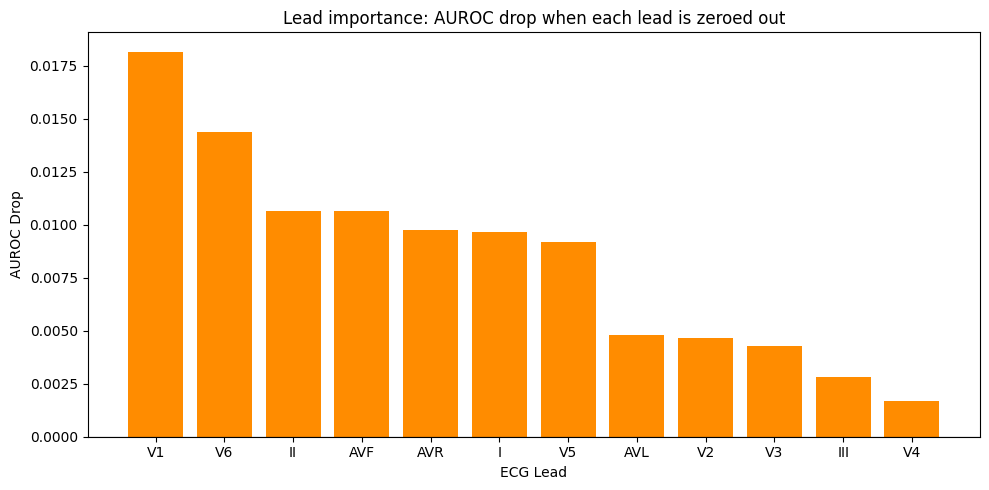

In [ ]:
sorted_leads = sorted(ablation_results.items(), key=lambda x: x[1]['auroc_drop'], reverse=True)

print('\nLeads ranked by importance (biggest AUROC drop = most important):')
for lead_name, result in sorted_leads:
    print(f'  {lead_name:>4}: drop of {result["auroc_drop"]:.4f}')

# Bar chart for the poster
lead_order = [l for l, _ in sorted_leads]
drops = [r['auroc_drop'] for _, r in sorted_leads]

plt.figure(figsize=(10, 5))
plt.bar(lead_order, drops, color='darkorange')
plt.axhline(y=0, color='black', linewidth=0.8)
plt.title('Lead importance: AUROC drop when each lead is zeroed out')
plt.xlabel('ECG Lead')
plt.ylabel('AUROC Drop')
plt.tight_layout()
plt.show()

In [ ]:
with open(os.path.join(DATA_DIR, 'lead_ablation_results.json'), 'w') as f:
    json.dump(ablation_results, f, indent=2)

print('Saved lead ablation results.')

Saved lead ablation results.


In [ ]:
final_results['lead_ablation'] = ablation_results

with open(os.path.join(DATA_DIR, 'final_results.json'), 'w') as f:
    json.dump(final_results, f, indent=2)

print('=== FINAL RESULTS SUMMARY ===\n')
print(f"Baseline (XGBoost):  AUROC {final_results['baseline']['test_macro_auroc']:.3f} | F1 {final_results['baseline']['test_macro_f1']:.3f}")
print(f"CNN (yours):         AUROC {final_results['cnn']['test_macro_auroc']:.3f} | F1 {final_results['cnn']['test_macro_f1']:.3f}")
print(f"\nTop 3 most important leads: V1, V6, II")
print(f"Bottom 3 least important leads: V4, III, V3")

=== FINAL RESULTS SUMMARY ===

Baseline (XGBoost):  AUROC 0.834 | F1 0.539
CNN (yours):         AUROC 0.910 | F1 0.688

Top 3 most important leads: V1, V6, II
Bottom 3 least important leads: V4, III, V3
